# Multiple Linear Regression Assignment - Geely Auto

## Business Objective

A Chinese automobile company, Geely Auto, wants to understand the factors affecting car prices in the American market.

The objective of this assignment is to build a Multiple Linear Regression model to predict car prices using independent variables available in the dataset.

The management wants to understand:
- Which variables significantly affect car prices
- How well these variables explain car prices
- The pricing dynamics in the American automobile market


In [1]:
# Importing required libraries

import numpy as np
import pandas as pd

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Statsmodels
import statsmodels.api as sm

# To ignore warnings
import warnings
warnings.filterwarnings('ignore')


Matplotlib is building the font cache; this may take a moment.


In [2]:
# Reading the dataset

car = pd.read_csv('CarPrice_Assignment.csv')

# Displaying first 5 rows
car.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


## Understanding the Dataset

Before building the regression model, it is important to understand the structure and characteristics of the dataset.

This step includes:
- Checking the shape of the dataset
- Understanding data types
- Identifying missing values
- Reviewing statistical summaries

In [3]:
# Shape of dataset

car.shape

(205, 26)

### Observation

The dataset contains 205 rows and 26 columns.
This indicates that the dataset has sufficient observations and features for building a regression model.

In [4]:
# Information about dataset

car.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

### Observation

The dataset contains both numerical and categorical variables.

No missing values are present in the dataset, which means data imputation is not required.

In [5]:
# Statistical summary of numerical variables

car.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


### Observation

The statistical summary provides insights into the distribution of numerical variables such as price, horsepower, wheelbase, and engine size.

There is noticeable variation in car prices, indicating that multiple factors may influence pricing.

In [6]:
# Checking missing values

car.isnull().sum()

car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64

### Observation

No missing values are present in the dataset.

Therefore, no missing value treatment is required before model building.

## Data Cleaning and Preparation

In this step, the dataset is cleaned and prepared for analysis.

The following tasks are performed:
- Extracting company names from the `CarName` column
- Correcting spelling inconsistencies in company names
- Removing unnecessary columns

In [7]:
# Extracting company name from CarName column

car['company_name'] = car['CarName'].apply(lambda x: x.split(' ')[0])

# Displaying unique company names
car['company_name'].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

### Observation

The `CarName` column contains both company name and car model.

For analysis purposes, only the company name is extracted because the company brand has a greater influence on pricing.

In [8]:
# Correcting spelling mistakes in company names

car['company_name'] = car['company_name'].replace({
    'maxda': 'mazda',
    'porcshce': 'porsche',
    'toyouta': 'toyota',
    'vokswagen': 'volkswagen',
    'vw': 'volkswagen'
})

# Checking updated company names
car['company_name'].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche', 'renault',
       'saab', 'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

### Observation

Some company names contained spelling inconsistencies.

These inconsistencies were corrected to ensure accurate analysis and avoid duplicate categories during dummy variable creation.

In [9]:
# Dropping CarName column

car.drop('CarName', axis=1, inplace=True)

# Displaying dataset
car.head()

,car_ID,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,company_name
0,1,3,gas,std,two,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,2,3,gas,std,two,convertible,rwd,front,88.6,168.8,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,3,1,gas,std,two,hatchback,rwd,front,94.5,171.2,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,4,2,gas,std,four,sedan,fwd,front,99.8,176.6,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,5,2,gas,std,four,sedan,4wd,front,99.4,176.6,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi


### Observation

The `CarName` column has been removed because the required company information has already been extracted into a separate column.

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the relationships between variables and identify factors affecting car prices.

The analysis includes:
- Distribution of target variable
- Correlation analysis
- Relationship between categorical variables and price
- Relationship between numerical variables and price

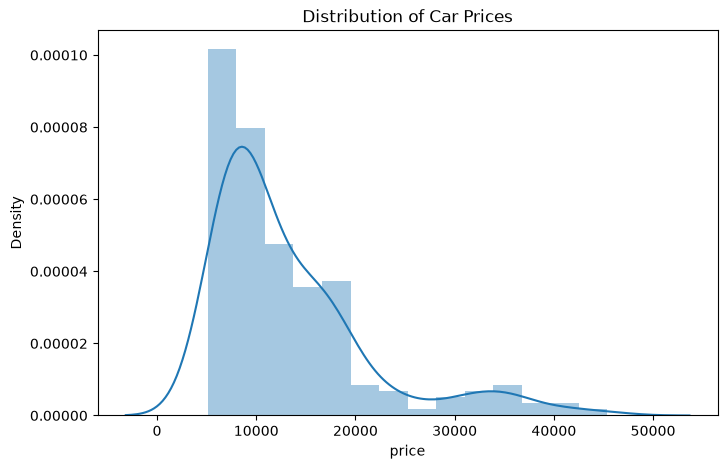

In [10]:
# Distribution of target variable - Price

plt.figure(figsize=(8,5))
sns.distplot(car['price'])
plt.title('Distribution of Car Prices')
plt.show()

### Observation

The distribution of car prices appears to be right-skewed.

Most cars belong to the lower and medium price range, while a few cars have very high prices.

### Correlation Analysis

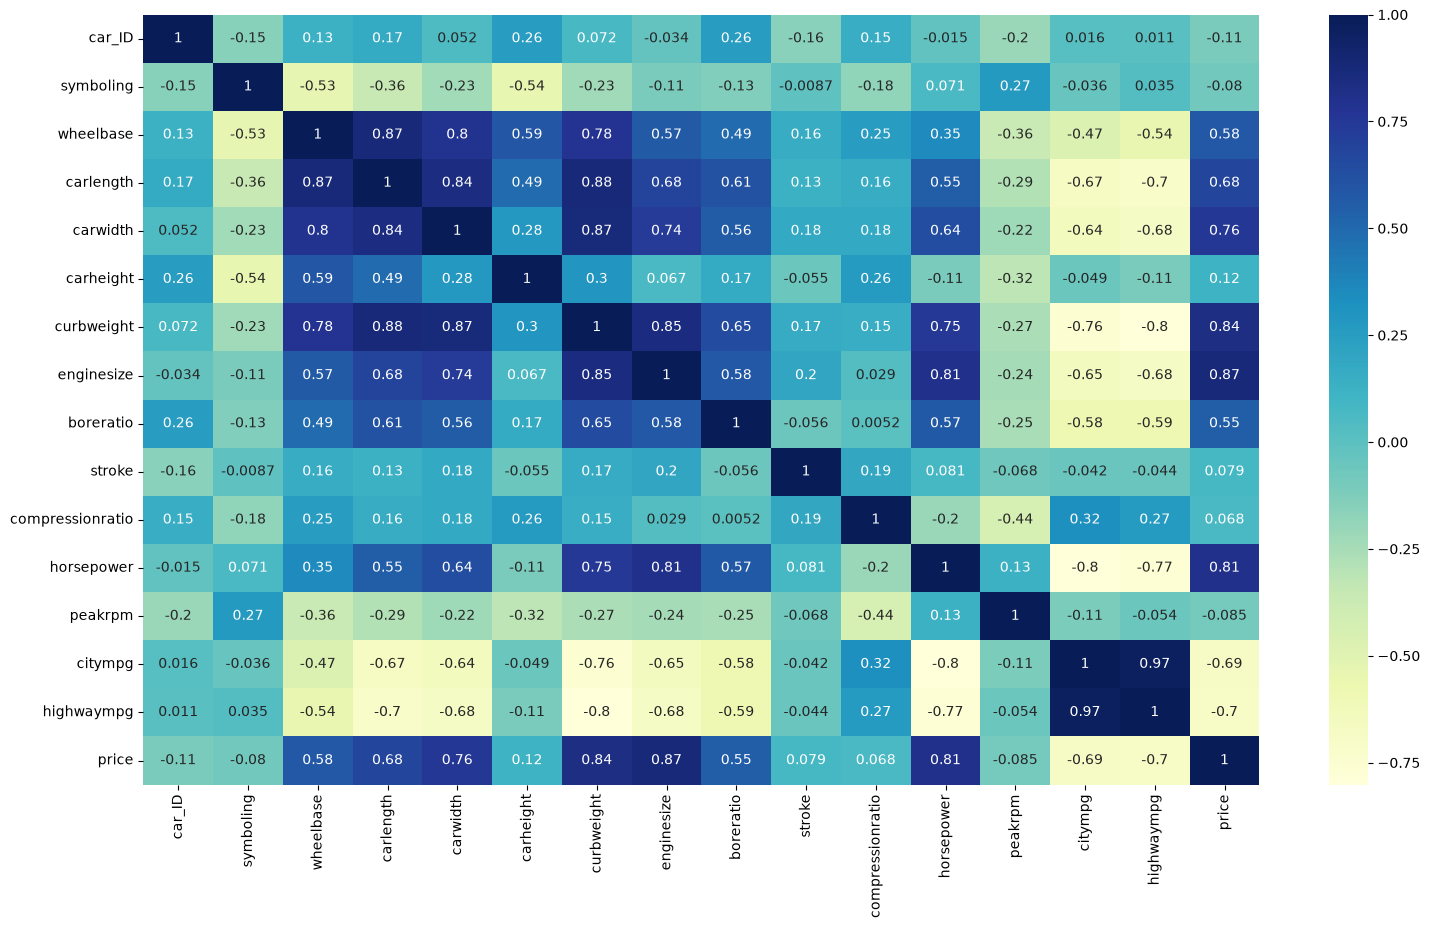

In [11]:
# Correlation heatmap

plt.figure(figsize=(18,10))
sns.heatmap(car.corr(numeric_only=True), annot=True, cmap='YlGnBu')
plt.show()

### Observation

Variables such as engine size, curb weight, horsepower, and wheelbase show strong positive correlation with car price.

This indicates that these variables may significantly influence the target variable.

### Company Name vs Price

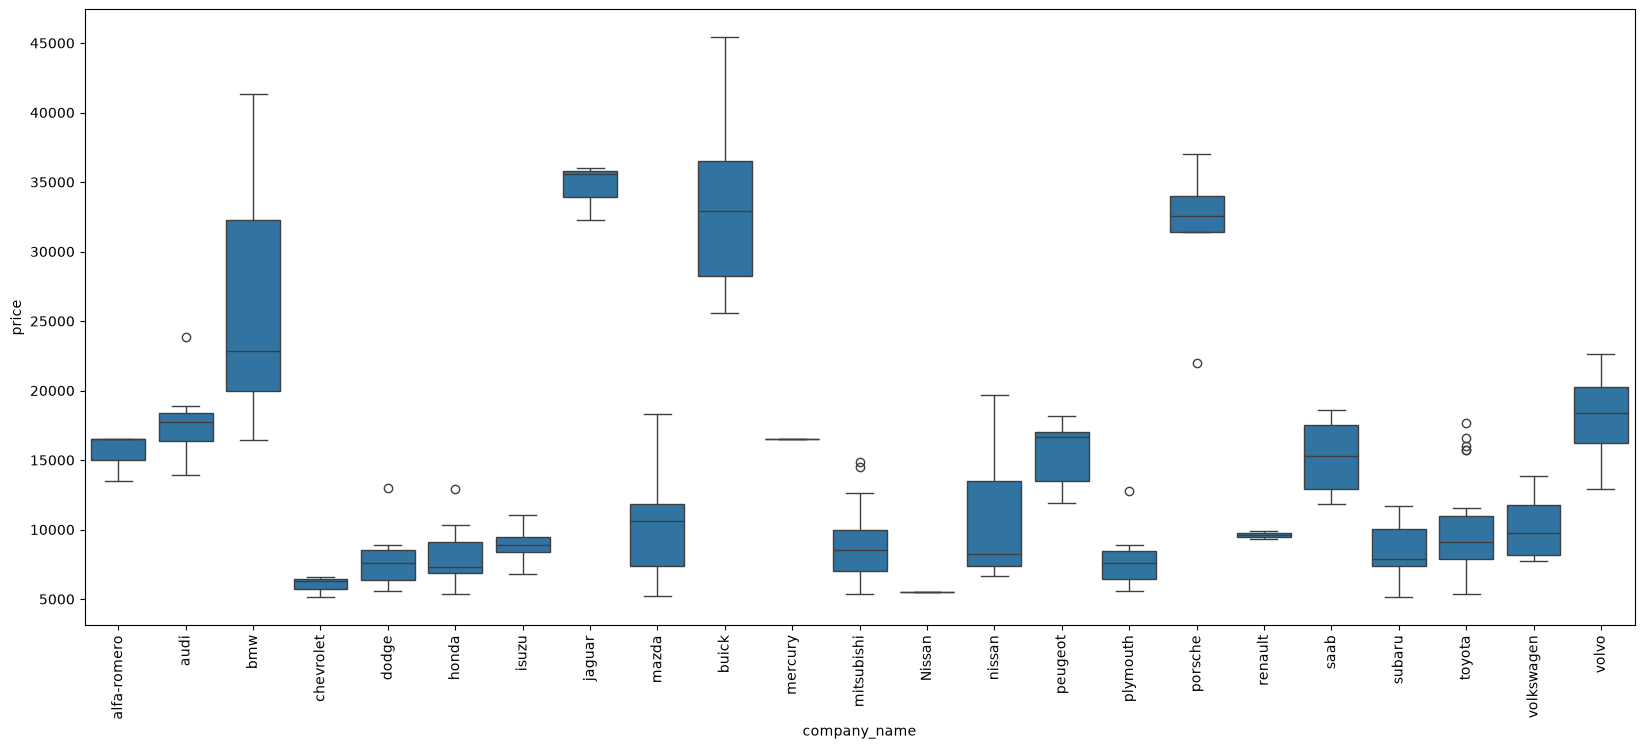

In [12]:
# Company name vs Price

plt.figure(figsize=(20,8))
sns.boxplot(x='company_name', y='price', data=car)
plt.xticks(rotation=90)
plt.show()

### Observation

Luxury car brands such as BMW, Jaguar, Porsche, and Buick tend to have higher prices compared to other brands.

This indicates that company brand has a strong influence on car pricing.

### Fuel Type vs Price

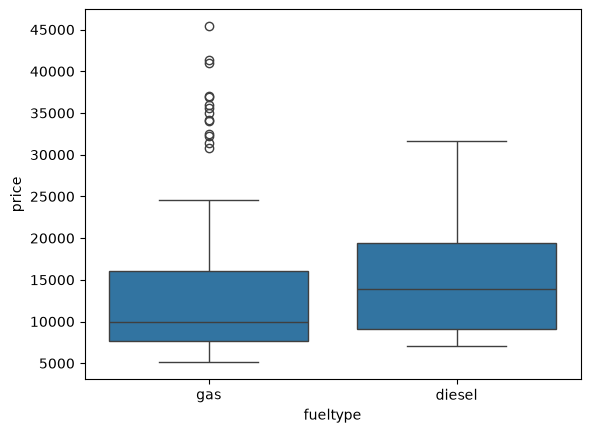

In [13]:
# Fuel type vs Price

sns.boxplot(x='fueltype', y='price', data=car)
plt.show()

### Observation

Diesel cars generally have slightly higher prices compared to gas cars.

### Horsepower vs Price

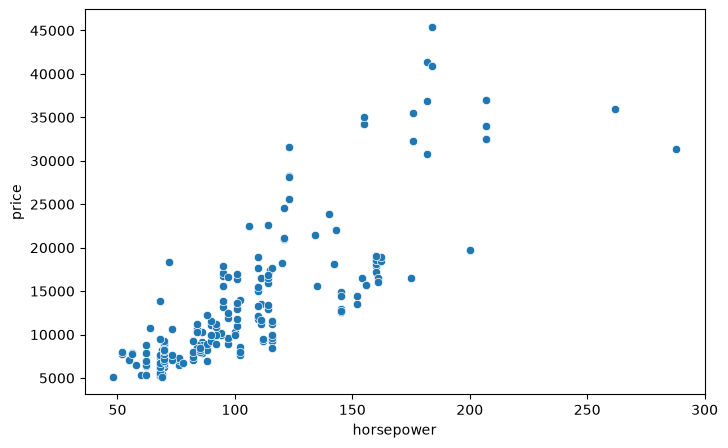

In [14]:
# Horsepower vs Price

plt.figure(figsize=(8,5))
sns.scatterplot(x='horsepower', y='price', data=car)
plt.show()

### Observation

There is a positive relationship between horsepower and car price.

Cars with higher horsepower generally tend to have higher prices.

## Dummy Variable Creation

Machine learning models cannot directly understand categorical variables.

Therefore, dummy variables are created for categorical columns using one-hot encoding.

In [15]:
# Creating dummy variables for categorical variables

categorical_cols = ['fueltype', 'aspiration', 'doornumber',
                    'carbody', 'drivewheel', 'enginelocation',
                    'enginetype', 'cylindernumber',
                    'fuelsystem', 'company_name']

# Creating dummies
dummy = pd.get_dummies(car[categorical_cols], drop_first=True)

# Adding dummy variables to original dataset
car = pd.concat([car, dummy], axis=1)

# Dropping original categorical columns
car.drop(categorical_cols, axis=1, inplace=True)

# Displaying dataset
car.head()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,...,company_name_nissan,company_name_peugeot,company_name_plymouth,company_name_porsche,company_name_renault,company_name_saab,company_name_subaru,company_name_toyota,company_name_volkswagen,company_name_volvo
0,1,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,False,False,False,False,False,False,False,False,False,False
1,2,3,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,False,False,False,False,False,False,False,False,False,False
2,3,1,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,...,False,False,False,False,False,False,False,False,False,False
3,4,2,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,...,False,False,False,False,False,False,False,False,False,False
4,5,2,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,...,False,False,False,False,False,False,False,False,False,False


### Observation

Dummy variables were created for categorical features using one-hot encoding.

The first category was dropped to avoid multicollinearity.

## Train-Test Split

The dataset is divided into training and testing sets.

The training set is used to build the model, while the testing set is used to evaluate model performance.

In [16]:
# Splitting dataset into X and y

X = car.drop('price', axis=1)
y = car['price']

In [17]:
# Splitting data into train and test sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

In [18]:
# Shape of training and testing datasets

print(X_train.shape)
print(X_test.shape)

(143, 66)
(62, 66)


### Observation

The dataset was split into 70% training data and 30% testing data.

This helps evaluate the model's performance on unseen data.

## Feature Scaling

Feature scaling is performed to bring numerical variables to a similar scale.

MinMaxScaler is used for scaling the training and testing datasets.

In [19]:
# Applying MinMaxScaler

scaler = MinMaxScaler()

In [20]:
# Numerical variables

num_vars = ['symboling', 'wheelbase', 'carlength', 'carwidth',
            'carheight', 'curbweight', 'enginesize',
            'boreratio', 'stroke', 'compressionratio',
            'horsepower', 'peakrpm', 'citympg', 'highwaympg']

In [21]:
# Scaling training data

X_train[num_vars] = scaler.fit_transform(X_train[num_vars])

# Scaling test data
X_test[num_vars] = scaler.transform(X_test[num_vars])

### Observation

Numerical variables were scaled using MinMaxScaler to improve model stability and performance.

## Model Building

In this step, a Multiple Linear Regression model is built using the training dataset.

The model is refined by removing statistically insignificant variables using p-values and multicollinearity analysis.

In [22]:
# Adding constant to training dataset

X_train_sm = sm.add_constant(X_train)

In [23]:
# Checking datatypes

X_train_sm.dtypes

const                      float64
car_ID                       int64
symboling                  float64
wheelbase                  float64
carlength                  float64
                            ...   
company_name_saab             bool
company_name_subaru           bool
company_name_toyota           bool
company_name_volkswagen       bool
company_name_volvo            bool
Length: 67, dtype: object

In [24]:
# Converting all columns to numeric type

X_train_sm = X_train_sm.astype(float)

# Building the regression model

lr = sm.OLS(y_train, X_train_sm).fit()

# Summary of model
lr.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     55.93
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           2.54e-48
Time:                        02:47:47   Log-Likelihood:                -1219.0
No. Observations:                 143   AIC:                             2558.
Df Residuals:                      83   BIC:                             2736.
Df Model:                          59                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                    -9329.5686   7176.989     -1.300      0.197   -2.36e+04    4945.174
car_ID                     100.6641     65.537      1.536      0.128     -29.687     231.015
symboling                  -92.3305   1358.209     -0.068      0.946   -2793.754    2609.093
wheelbase                 6450.5814   3637.984      1.773      0.080    -785.222    1.37e+04
carlength                -5845.4758   3637.054     -1.607      0.112   -1.31e+04    1388.478
carwidth                  8471.6107   3690.017      2.296      0.024    1132.316    1.58e+04
carheight                -4726.6807   2186.399     -2.162      0.034   -9075.340    -378.022
curbweight                1.231e+04   4743.033      2.595      0.011    2875.880    2.17e+04
enginesize                7.671e+04    1.7e+04      4.518      0.000    4.29e+04     1.1e+05
boreratio                -2.387e+04   6211.649     -3.843      0.000   -3.62e+04   -1.15e+04
stroke                   -8207.1292   3198.806     -2.566      0.012   -1.46e+04   -1844.832
compressionratio         -1.424e+04   9852.477     -1.445      0.152   -3.38e+04    5359.436
horsepower               -8776.7392   7635.673     -1.149      0.254    -2.4e+04    6410.306
peakrpm                   7194.9719   1859.461      3.869      0.000    3496.578    1.09e+04
citympg                  -1583.6707   5561.714     -0.285      0.777   -1.26e+04    9478.356
highwaympg                5107.1681   5019.138      1.018      0.312   -4875.695    1.51e+04
fueltype_gas             -1.013e+04   4288.552     -2.363      0.020   -1.87e+04   -1603.121
aspiration_turbo          2936.8738   1054.857      2.784      0.007     838.806    5034.942
doornumber_two            -365.1870    557.315     -0.655      0.514   -1473.664     743.290
carbody_hardtop          -3210.5556   2072.275     -1.549      0.125   -7332.227     911.116
carbody_hatchback        -3228.3828   1649.476     -1.957      0.054   -6509.124      52.358
carbody_sedan            -2703.8403   1725.913     -1.567      0.121   -6136.612     728.932
carbody_wagon            -2234.1301   1823.460     -1.225      0.224   -5860.919    1392.659
drivewheel_fwd              87.0309    898.578      0.097      0.923   -1700.205    1874.267
drivewheel_rwd            1109.3873   1258.263      0.882      0.380   -1393.246    3612.021
enginelocation_rear       8718.0959   2444.058      3.567      0.001    3856.963    1.36e+04
enginetype_dohcv          1.064e+04   6237.648      1.706      0.092   -1766.122     2.3e+04
enginetype_l              7339.7084   2507.707      2.927      0.004    2351.980    1.23e+04
enginetype_ohc             226.5352   1617.799      0.140      0.889   -2991.202    3444.272
enginetype_ohcf           4053.5508   1779.043      2.279      0.025     515.105    7591.996
enginetype_ohc

In [25]:
# Checking p-values

lr.pvalues.sort_values(ascending=False)

symboling               0.945965
company_name_nissan     0.940481
drivewheel_fwd          0.923076
fuelsystem_idi          0.901979
enginetype_ohc          0.888978
                          ...   
cylindernumber_three    0.000330
boreratio               0.000237
peakrpm                 0.000216
fuelsystem_mfi          0.000164
enginesize              0.000020
Length: 67, dtype: float64

### Observation

The initial regression model was built using all independent variables.

Variables with high p-values indicate statistical insignificance and may need to be removed for model optimization.

symboling

In [26]:
# Dropping insignificant variable

X_train_new = X_train_sm.drop('symboling', axis=1)

In [27]:
# Rebuilding model after removing symboling

lr_1 = sm.OLS(y_train, X_train_new).fit()

# Summary of updated model
lr_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     57.58
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           3.33e-49
Time:                        02:47:47   Log-Likelihood:                -1219.0
No. Observations:                 143   AIC:                             2556.
Df Residuals:                      84   BIC:                             2731.
Df Model:                          58                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                    -9400.5319   7058.471     -1.332      0.187   -2.34e+04    4636.011
car_ID                     101.2427     64.596      1.567      0.121     -27.214     229.699
wheelbase                 6499.3958   3545.218      1.833      0.070    -550.660    1.35e+04
carlength                -5822.8705   3600.298     -1.617      0.110    -1.3e+04    1336.716
carwidth                  8426.1272   3607.286      2.336      0.022    1252.643    1.56e+04
carheight                -4714.0480   2165.541     -2.177      0.032   -9020.465    -407.631
curbweight                1.232e+04   4710.705      2.616      0.011    2955.343    2.17e+04
enginesize                7.659e+04   1.68e+04      4.562      0.000    4.32e+04     1.1e+05
boreratio                -2.386e+04   6170.794     -3.866      0.000   -3.61e+04   -1.16e+04
stroke                   -8189.6485   3169.506     -2.584      0.011   -1.45e+04   -1886.738
compressionratio         -1.424e+04   9793.919     -1.454      0.150   -3.37e+04    5238.618
horsepower               -8714.1699   7534.951     -1.156      0.251   -2.37e+04    6269.907
peakrpm                   7190.1664   1847.075      3.893      0.000    3517.055    1.09e+04
citympg                  -1581.8913   5528.603     -0.286      0.775   -1.26e+04    9412.341
highwaympg                5123.8855   4983.319      1.028      0.307   -4785.991     1.5e+04
fueltype_gas             -1.017e+04   4236.641     -2.399      0.019   -1.86e+04   -1740.263
aspiration_turbo          2933.3486   1047.321      2.801      0.006     850.637    5016.061
doornumber_two            -375.5261    532.974     -0.705      0.483   -1435.403     684.351
carbody_hardtop          -3212.7265   2059.716     -1.560      0.123   -7308.697     883.244
carbody_hatchback        -3215.8530   1629.405     -1.974      0.052   -6456.103      24.397
carbody_sedan            -2688.5493   1701.024     -1.581      0.118   -6071.222     694.123
carbody_wagon            -2221.9144   1803.801     -1.232      0.221   -5808.970    1365.142
drivewheel_fwd              84.6132    892.538      0.095      0.925   -1690.297    1859.524
drivewheel_rwd            1093.6539   1229.444      0.890      0.376   -1351.231    3538.538
enginelocation_rear       8737.2870   2413.272      3.621      0.001    3938.230    1.35e+04
enginetype_dohcv          1.064e+04   6200.422      1.716      0.090   -1692.941     2.3e+04
enginetype_l              7322.0146   2479.341      2.953      0.004    2391.572    1.23e+04
enginetype_ohc             236.7697   1601.206      0.148      0.883   -2947.405    3420.944
enginetype_ohcf           4055.1998   1768.307      2.293      0.024     538.728    7571.672
enginetype_ohcv           -639.8400   1407.137     -0.455      0.650   -3438.086    2158.406
enginetype_rot

In [28]:
# Checking updated p-values

lr_1.pvalues.sort_values(ascending=False)

company_name_nissan    0.937586
drivewheel_fwd         0.924699
fuelsystem_idi         0.905744
enginetype_ohc         0.882800
fuelsystem_spdi        0.873617
                         ...   
boreratio              0.000217
peakrpm                0.000198
fuelsystem_mfi         0.000030
enginesize             0.000017
fuelsystem_spfi        0.000008
Length: 66, dtype: float64

### Observation

The variable `symboling` was removed because it had a very high p-value, indicating statistical insignificance.

The model was rebuilt after removing the variable.

In [29]:
# Removing company_name_nissan

X_train_new = X_train_new.drop('company_name_nissan', axis=1)

In [30]:
# Rebuilding model

lr_2 = sm.OLS(y_train, X_train_new).fit()

# Model summary
lr_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     59.28
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           4.31e-50
Time:                        02:47:47   Log-Likelihood:                -1219.0
No. Observations:                 143   AIC:                             2554.
Df Residuals:                      85   BIC:                             2726.
Df Model:                          57                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                    -9430.4630   7006.850     -1.346      0.182   -2.34e+04    4501.031
car_ID                     100.5060     63.537      1.582      0.117     -25.822     226.834
wheelbase                 6519.7365   3515.015      1.855      0.067    -469.055    1.35e+04
carlength                -5830.3948   3577.921     -1.630      0.107   -1.29e+04    1283.470
carwidth                  8442.3903   3580.223      2.358      0.021    1323.948    1.56e+04
carheight                -4714.7398   2152.826     -2.190      0.031   -8995.136    -434.344
curbweight                1.229e+04   4662.495      2.636      0.010    3018.152    2.16e+04
enginesize                 7.65e+04   1.66e+04      4.595      0.000    4.34e+04     1.1e+05
boreratio                -2.382e+04   6115.299     -3.895      0.000    -3.6e+04   -1.17e+04
stroke                   -8171.5623   3142.595     -2.600      0.011   -1.44e+04   -1923.241
compressionratio         -1.416e+04   9690.742     -1.462      0.148   -3.34e+04    5104.608
horsepower               -8670.9985   7470.813     -1.161      0.249   -2.35e+04    6182.979
peakrpm                   7181.2508   1832.774      3.918      0.000    3537.205    1.08e+04
citympg                  -1601.9150   5490.340     -0.292      0.771   -1.25e+04    9314.351
highwaympg                5124.7284   4954.089      1.034      0.304   -4725.328     1.5e+04
fueltype_gas             -1.015e+04   4205.169     -2.413      0.018   -1.85e+04   -1785.621
aspiration_turbo          2933.5826   1041.176      2.818      0.006     863.446    5003.719
doornumber_two            -369.1480    523.662     -0.705      0.483   -1410.329     672.033
carbody_hardtop          -3223.7465   2042.882     -1.578      0.118   -7285.544     838.051
carbody_hatchback        -3220.5924   1618.740     -1.990      0.050   -6439.081      -2.104
carbody_sedan            -2686.0520   1690.755     -1.589      0.116   -6047.726     675.622
carbody_wagon            -2219.7897   1793.023     -1.238      0.219   -5784.800    1345.221
drivewheel_fwd              79.1116    884.568      0.089      0.929   -1679.647    1837.870
drivewheel_rwd            1087.1371   1219.449      0.891      0.375   -1337.454    3511.728
enginelocation_rear       8692.7438   2331.929      3.728      0.000    4056.244    1.33e+04
enginetype_dohcv          1.059e+04   6131.251      1.727      0.088   -1603.474    2.28e+04
enginetype_l              7355.2718   2428.590      3.029      0.003    2526.584    1.22e+04
enginetype_ohc             241.8062   1590.541      0.152      0.880   -2920.616    3404.228
enginetype_ohcf           4111.6627   1606.098      2.560      0.012     918.309    7305.016
enginetype_ohcv           -646.9839   1395.961     -0.463      0.644   -3422.528    2128.560
enginetype_rot

### Observation

The variable `company_name_nissan` was removed because it had a very high p-value, indicating low statistical significance.

The model was rebuilt after removing the variable.

In [31]:
# Removing drivewheel_fwd

X_train_new = X_train_new.drop('drivewheel_fwd', axis=1)

In [32]:
# Rebuilding updated model

lr_3 = sm.OLS(y_train, X_train_new).fit()

# Model summary
lr_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     61.05
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           5.49e-51
Time:                        02:47:47   Log-Likelihood:                -1219.0
No. Observations:                 143   AIC:                             2552.
Df Residuals:                      86   BIC:                             2721.
Df Model:                          56                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                    -9371.5896   6935.509     -1.351      0.180   -2.32e+04    4415.747
car_ID                      99.6199     62.396      1.597      0.114     -24.420     223.660
wheelbase                 6574.7498   3440.756      1.911      0.059    -265.248    1.34e+04
carlength                -5806.8762   3547.605     -1.637      0.105   -1.29e+04    1245.529
carwidth                  8476.5620   3539.186      2.395      0.019    1440.893    1.55e+04
carheight                -4738.3313   2124.246     -2.231      0.028   -8961.193    -515.470
curbweight                1.211e+04   4209.211      2.878      0.005    3746.129    2.05e+04
enginesize                7.652e+04   1.65e+04      4.624      0.000    4.36e+04    1.09e+05
boreratio                -2.379e+04   6073.117     -3.918      0.000   -3.59e+04   -1.17e+04
stroke                   -8156.1492   3119.716     -2.614      0.011   -1.44e+04   -1954.359
compressionratio         -1.399e+04   9432.712     -1.483      0.142   -3.27e+04    4764.961
horsepower               -8576.3358   7352.677     -1.166      0.247   -2.32e+04    6040.302
peakrpm                   7171.9006   1819.206      3.942      0.000    3555.439    1.08e+04
citympg                  -1670.3381   5405.327     -0.309      0.758   -1.24e+04    9075.097
highwaympg                5192.0538   4868.239      1.067      0.289   -4485.685    1.49e+04
fueltype_gas             -1.004e+04   4023.856     -2.496      0.014    -1.8e+04   -2045.369
aspiration_turbo          2934.4110   1035.112      2.835      0.006     876.676    4992.146
doornumber_two            -368.5641    520.593     -0.708      0.481   -1403.468     666.340
carbody_hardtop          -3248.9697   2011.618     -1.615      0.110   -7247.934     749.995
carbody_hatchback        -3242.3264   1591.137     -2.038      0.045   -6405.403     -79.250
carbody_sedan            -2707.6130   1663.800     -1.627      0.107   -6015.137     599.911
carbody_wagon            -2234.3477   1775.291     -1.259      0.212   -5763.509    1294.813
drivewheel_rwd            1013.4688    894.001      1.134      0.260    -763.747    2790.685
enginelocation_rear       8684.6836   2316.709      3.749      0.000    4079.219    1.33e+04
enginetype_dohcv          1.053e+04   6062.428      1.737      0.086   -1521.900    2.26e+04
enginetype_l              7369.1511   2409.608      3.058      0.003    2579.009    1.22e+04
enginetype_ohc             247.2346   1580.189      0.156      0.876   -2894.078    3388.547
enginetype_ohcf           4120.2281   1593.967      2.585      0.011     951.527    7288.929
enginetype_ohcv           -640.0903   1385.769     -0.462      0.645   -3394.908    2114.728
enginetype_rotor          1.589e+04   4184.814      3.796      0.000    7568.063    2.42e+04
cylindernumber

In [33]:
# Checking updated p-values

lr_3.pvalues.sort_values(ascending=False)

fuelsystem_idi          0.915407
enginetype_ohc          0.876038
fuelsystem_spdi         0.867406
company_name_jaguar     0.800490
fuelsystem_mpfi         0.795984
                          ...   
cylindernumber_three    0.000206
boreratio               0.000179
peakrpm                 0.000164
company_name_peugeot    0.000163
enginesize              0.000013
Length: 64, dtype: float64

### Observation

The variable `drivewheel_fwd` was removed because it had a very high p-value, indicating low statistical significance.

The regression model was rebuilt after removing the variable.

In [34]:
# Removing fuelsystem_idi

X_train_new = X_train_new.drop('fuelsystem_idi', axis=1)

In [35]:
# Final optimized model

lr_final = sm.OLS(y_train, X_train_new).fit()

# Final model summary
lr_final.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.975
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     61.05
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           5.49e-51
Time:                        02:47:47   Log-Likelihood:                -1219.0
No. Observations:                 143   AIC:                             2552.
Df Residuals:                      86   BIC:                             2721.
Df Model:                          56                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                    -8698.6486   1.26e+04     -0.688      0.493   -3.38e+04    1.64e+04
car_ID                      99.6199     62.396      1.597      0.114     -24.420     223.660
wheelbase                 6574.7498   3440.756      1.911      0.059    -265.248    1.34e+04
carlength                -5806.8762   3547.605     -1.637      0.105   -1.29e+04    1245.529
carwidth                  8476.5620   3539.186      2.395      0.019    1440.893    1.55e+04
carheight                -4738.3313   2124.246     -2.231      0.028   -8961.193    -515.470
curbweight                1.211e+04   4209.211      2.878      0.005    3746.129    2.05e+04
enginesize                7.652e+04   1.65e+04      4.624      0.000    4.36e+04    1.09e+05
boreratio                -2.379e+04   6073.117     -3.918      0.000   -3.59e+04   -1.17e+04
stroke                   -8156.1492   3119.716     -2.614      0.011   -1.44e+04   -1954.359
compressionratio         -1.399e+04   9432.712     -1.483      0.142   -3.27e+04    4764.961
horsepower               -8576.3358   7352.677     -1.166      0.247   -2.32e+04    6040.302
peakrpm                   7171.9006   1819.206      3.942      0.000    3555.439    1.08e+04
citympg                  -1670.3381   5405.327     -0.309      0.758   -1.24e+04    9075.097
highwaympg                5192.0538   4868.239      1.067      0.289   -4485.685    1.49e+04
fueltype_gas             -1.072e+04   8005.192     -1.339      0.184   -2.66e+04    5196.324
aspiration_turbo          2934.4110   1035.112      2.835      0.006     876.676    4992.146
doornumber_two            -368.5641    520.593     -0.708      0.481   -1403.468     666.340
carbody_hardtop          -3248.9697   2011.618     -1.615      0.110   -7247.934     749.995
carbody_hatchback        -3242.3264   1591.137     -2.038      0.045   -6405.403     -79.250
carbody_sedan            -2707.6130   1663.800     -1.627      0.107   -6015.137     599.911
carbody_wagon            -2234.3477   1775.291     -1.259      0.212   -5763.509    1294.813
drivewheel_rwd            1013.4688    894.001      1.134      0.260    -763.747    2790.685
enginelocation_rear       8684.6836   2316.709      3.749      0.000    4079.219    1.33e+04
enginetype_dohcv          1.053e+04   6062.428      1.737      0.086   -1521.900    2.26e+04
enginetype_l              7369.1511   2409.608      3.058      0.003    2579.009    1.22e+04
enginetype_ohc             247.2346   1580.189      0.156      0.876   -2894.078    3388.547
enginetype_ohcf           4120.2281   1593.967      2.585      0.011     951.527    7288.929
enginetype_ohcv           -640.0903   1385.769     -0.462      0.645   -3394.908    2114.728
enginetype_rotor          1.589e+04   4184.814      3.796      0.000    7568.063    2.42e+04
cylindernumber

### Observation

The variable `fuelsystem_idi` was removed because of its high p-value.

After removing statistically insignificant variables, the final optimized regression model was obtained.

## Residual Analysis

Residual analysis is performed to check whether the error terms are normally distributed.

This helps validate the assumptions of linear regression.

In [36]:
# Predicting on training dataset

y_train_pred = lr_final.predict(X_train_new)

# Residuals

residuals = y_train - y_train_pred

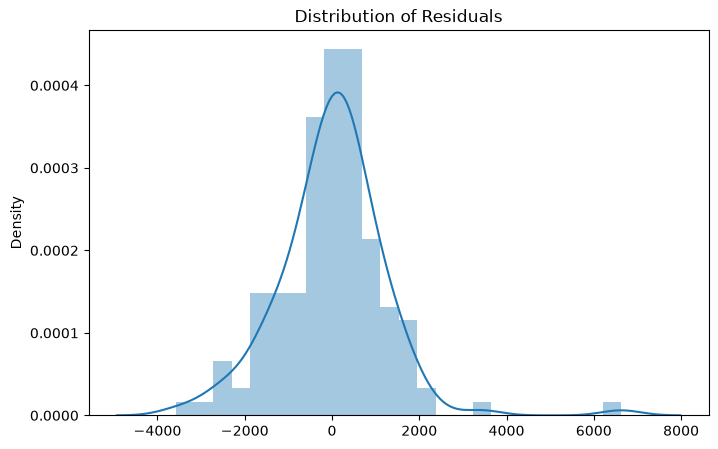

In [37]:
# Distribution of residuals

plt.figure(figsize=(8,5))
sns.distplot(residuals)
plt.title('Distribution of Residuals')
plt.show()

### Observation

The residuals appear to follow a normal distribution pattern.

This indicates that the assumptions of linear regression are reasonably satisfied.

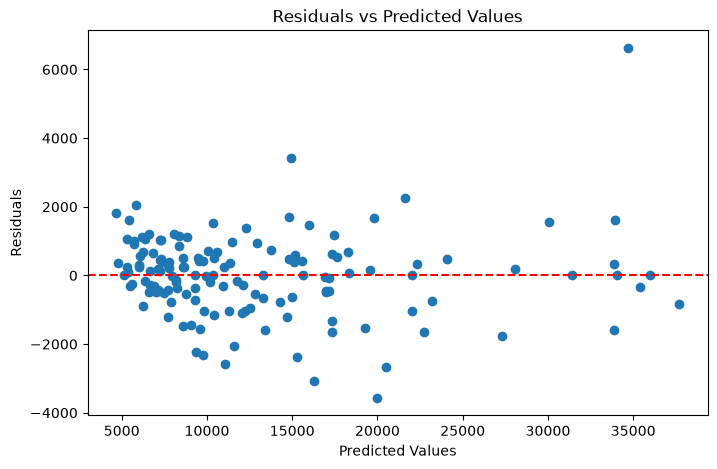

In [38]:
# Residual scatter plot

plt.figure(figsize=(8,5))
plt.scatter(y_train_pred, residuals)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()

### Observation

The residuals are randomly distributed around zero without any visible pattern.

This suggests that the model does not show major signs of heteroscedasticity.

## Prediction on Test Dataset

The final optimized model is now used to make predictions on the test dataset.

In [39]:
# Preparing test dataset

X_test_sm = sm.add_constant(X_test)

In [40]:
# Aligning test dataset columns with final model

X_test_sm = X_test_sm[X_train_new.columns]

In [41]:
# Converting datatype to float

X_test_sm = X_test_sm.astype(float)

In [42]:
# Predicting on test dataset

y_pred = lr_final.predict(X_test_sm)

## Model Evaluation

The performance of the regression model is evaluated using R-squared score on the test dataset.

In [43]:
# R-squared score on test dataset

r2_score(y_test, y_pred)

0.8208175578616212

### Observation

The R-squared score on the test dataset indicates that the model performs well on unseen data and explains a significant proportion of variance in car prices.

## Final Conclusion

A Multiple Linear Regression model was successfully built to predict car prices.

Key findings from the analysis include:
- Engine size, horsepower, curb weight, and brand name significantly affect car prices.
- Luxury brands generally have higher car prices compared to economy brands.
- The final optimized model achieved a strong R-squared score, indicating good predictive performance.

The model can help Geely Auto understand pricing dynamics in the American automobile market and support strategic business decisions.